
##  FISH ANALYSIS USING WEIGHT
 ## Identifying classes and checking imbalance of data(Data Quality)


In [9]:
import pandas as pd
import matplotlib.pyplot as plt


## Load the dataset
## Understand the dataset#

In [3]:
# Step 1: Load the dataset
df = pd.read_csv("Fish.csv")

# Step 2: Understand the dataset
print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

First five rows:
  Species  Weight  Length1  Length2  Length3   Height   Width
0   Bream   242.0     23.2     25.4     30.0  11.5200  4.0200
1   Bream   290.0     24.0     26.3     31.2  12.4800  4.3056
2   Bream   340.0     23.9     26.5     31.1  12.3778  4.6961
3   Bream   363.0     26.3     29.0     33.5  12.7300  4.4555
4   Bream   430.0     26.5     29.0     34.0  12.4440  5.1340

Dataset shape: (159, 7)

Column names:
['Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']

Data types:
Species     object
Weight     float64
Length1    float64
Length2    float64
Length3    float64
Height     float64
Width      float64
dtype: object


## Check data quality

In [4]:
# Step 3: Check data quality
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64

Duplicate rows: 0


## Identify fish classes
## Check the selected feature

In [5]:
# Step 4: Identify fish classes
print("\nFish species/classes:")
print(df["Species"].unique())

print("\nNumber of classes:", df["Species"].nunique())

print("\nRecords per class:")
print(df["Species"].value_counts())

# Step 5: Check the selected feature
print("\nWeight statistics:")
print(df["Weight"].describe())


Fish species/classes:
['Bream' 'Roach' 'Whitefish' 'Parkki' 'Perch' 'Pike' 'Smelt']

Number of classes: 7

Records per class:
Species
Perch        56
Bream        35
Roach        20
Pike         17
Smelt        14
Parkki       11
Whitefish     6
Name: count, dtype: int64

Weight statistics:
count     159.000000
mean      398.326415
std       357.978317
min         0.000000
25%       120.000000
50%       273.000000
75%       650.000000
max      1650.000000
Name: Weight, dtype: float64


## visualization

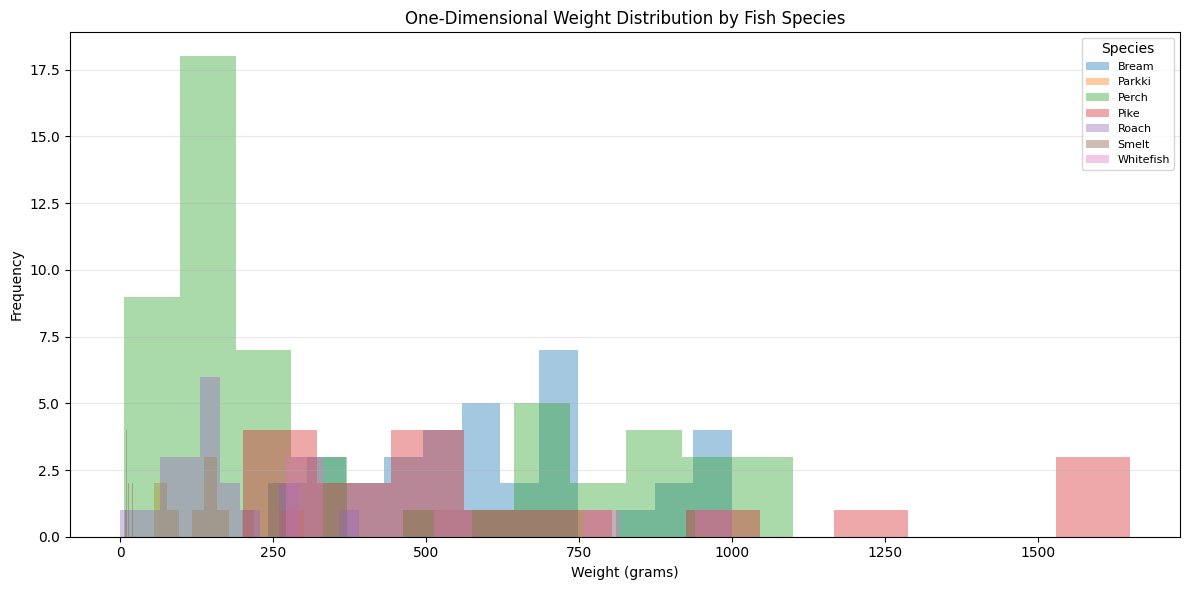

In [6]:
# Step 6: One-dimensional visualization
plt.figure(figsize=(12, 6))

species_list = sorted(df["Species"].unique())

for species in species_list:
    values = df.loc[df["Species"] == species, "Weight"]
    plt.hist(values, bins=12, alpha=0.4, label=species)

plt.xlabel("Weight (grams)")
plt.ylabel("Frequency")
plt.title("One-Dimensional Weight Distribution by Fish Species")
plt.legend(title="Species", fontsize=8)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Compare weight statistics by class

In [7]:
# Step 7: Compare weight statistics by class
print("\nWeight statistics by species:")
print(
    df.groupby("Species")["Weight"]
      .agg(["count", "mean", "min", "max"])
      .round(2)
)


Weight statistics by species:
           count    mean    min     max
Species                                
Bream         35  617.83  242.0  1000.0
Parkki        11  154.82   55.0   300.0
Perch         56  382.24    5.9  1100.0
Pike          17  718.71  200.0  1650.0
Roach         20  152.05    0.0   390.0
Smelt         14   11.18    6.7    19.9
Whitefish      6  531.00  270.0  1000.0



# 🐟 Final Conclusion: Fish Analysis

- **Total records:** 159
- **Number of fish species:** 7
- **Most common species:** Perch
- **Highest average weight:** Pike (718.71 g)
- **Lowest average weight:** Smelt (11.18 g)

### Machine Learning Problem
**Task:** Predict fish species using weight alone.

- **Input (X):** Weight
- **Target (y):** Species
- **Problem type:** Multiclass classification

### Interpretation
Fish species have different weight distributions, but some distributions
may overlap. Therefore, weight can help predict species, although using
additional features such as length and height may improve classification.


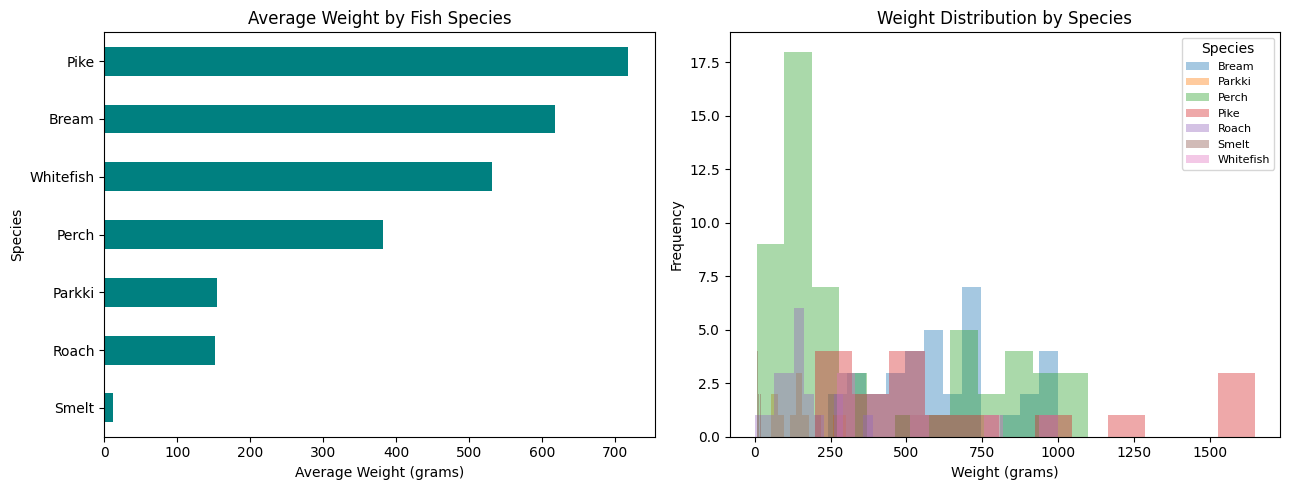

In [10]:
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Calculate findings from the dataset
species_counts = df["Species"].value_counts()
mean_weights = df.groupby("Species")["Weight"].mean()
heaviest = mean_weights.idxmax()
lightest = mean_weights.idxmin()

display(Markdown(f"""
# 🐟 Final Conclusion: Fish Analysis

- **Total records:** {len(df)}
- **Number of fish species:** {df['Species'].nunique()}
- **Most common species:** {species_counts.idxmax()}
- **Highest average weight:** {heaviest} ({mean_weights[heaviest]:.2f} g)
- **Lowest average weight:** {lightest} ({mean_weights[lightest]:.2f} g)

### Machine Learning Problem
**Task:** Predict fish species using weight alone.

- **Input (X):** Weight
- **Target (y):** Species
- **Problem type:** Multiclass classification

### Interpretation
Fish species have different weight distributions, but some distributions
may overlap. Therefore, weight can help predict species, although using
additional features such as length and height may improve classification.
"""))

# Visual summary
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Average weight by species
mean_weights.sort_values().plot(
    kind="barh", ax=axes[0], color="teal"
)
axes[0].set_title("Average Weight by Fish Species")
axes[0].set_xlabel("Average Weight (grams)")
axes[0].set_ylabel("Species")

# Weight distribution by species
for species in sorted(df["Species"].dropna().unique()):
    axes[1].hist(
        df.loc[df["Species"] == species, "Weight"].dropna(),
        bins=12, alpha=0.4, label=species
    )

axes[1].set_title("Weight Distribution by Species")
axes[1].set_xlabel("Weight (grams)")
axes[1].set_ylabel("Frequency")
axes[1].legend(title="Species", fontsize=8)

plt.tight_layout()
plt.show()